# Used Cars Market — Complete Exploratory Data Analysis (EDA)



## Project overview
This project analyzes used-car listings to understand asking prices, displayed prices, mileage, model year, fuel type, transmission, discounts, brands, and cities.



### Project objectives
1. Inspect and clean the used-car dataset.
2. Calculate meaningful summary statistics and business metrics.
3. Compare prices across companies, fuel types, transmission types, and cities.
4. Explore how mileage and vehicle age relate to price.
5. Visualize patterns and summarize the main findings.



**Data note:** The attached data was extracted from the output of the uploaded `cars.ipynb`. It contains 14 unique listings, so findings are exploratory and should not be generalized to the whole used-car market. `Price` and `Display Price` are represented in lakh units based on the original scraped labels (`₹5.91L`, `₹5.61 lakh`). `Price` is treated as the original/listed reference price and `Display Price` as the displayed price; verify this meaning if the source website changes.



## 1. Import libraries

**Theory:** Pandas manages tabular data, NumPy supports numerical operations, Matplotlib creates charts, and Seaborn makes statistical visualizations easier. These libraries are the foundation of the analysis.

In [7]:
import numpy as np
import pandas as pd
import json
import requests
from pandas import json_normalize
import matplotlib.pyplot as plt
import re
from bs4 import BeautifulSoup
import warnings
warnings.filterwarnings("ignore")
import seaborn as sns
import time

## 2. Load the dataset

**Theory:** Loading data is the first step of EDA. We inspect the shape and first rows to confirm that the file has been read correctly. Keep the CSV in the same folder as this notebook.

In [8]:
url = "https://www.cars24.com/buy-used-car/?f=listingPrice%3Abw%3A0%2C19500000&sort=bestmatch&serveWarrantyCount=true&listingSource=TabFilter"
response = requests.get(url)
response

<Response [200]>

In [9]:
pagecontent = response.content

In [10]:
soup = BeautifulSoup(pagecontent,'html.parser')

In [11]:
pname = soup.find("span", class_="sc-ksBlki dxpZAa")
pname

<span class="sc-ksBlki dxpZAa" id="">2018 Tata Tiago</span>

In [12]:
Car = []
Model = []
Running = []
Fuel = []
Transmission = []
Registration = []
Price = []
DisplayPrice = []
EMI = []
Location = []
Badge = []

total_time = time.time()
for i in range(1, 1600):
    start_time = time.time()

    URL = "https://www.cars24.com/buy-used-car/?f=listingPrice%3Abw%3A0%2C19500000&sort=bestmatch&serveWarrantyCount=true&listingSource=TabFilter"
    page = requests.get(URL, timeout=20, headers={'User-Agent': 'Mozilla/5.0'})
    soup = BeautifulSoup(page.text, "html.parser")

    for x in soup.find_all('div', class_='styles_normalCardWrapper__qDZjq'):
        car_name = x.select_one('span.sc-ksBlki.dxpZAa')
        model_name = x.select_one('span.sc-ksBlki.gTPzAB')
        stats = [
            p.get_text(" ", strip=True)
            for p in x.select('div.sc-dEVLtH p.sc-ksBlki.knJTXq')
        ]
        emi = x.select_one('span.sc-jRwbcY.fnPJMJ p')
        price = x.select_one('p.sc-ksBlki.fAywVv')
        display_price = x.select_one('p.sc-ksBlki.dMXwkk')
        location = x.select_one('div.styles_hubAddress__URioy p.sc-ksBlki.gTPzAB')
        badge = x.select_one('span.sc-ksBlki.CJDwk')

        Car.append(car_name.get_text(" ", strip=True) if car_name else np.nan)
        Model.append(model_name.get_text(" ", strip=True) if model_name else np.nan)
        Running.append(stats[0] if len(stats) > 0 else np.nan)
        Fuel.append(stats[1] if len(stats) > 1 else np.nan)
        Transmission.append(stats[2] if len(stats) > 2 else np.nan)
        Registration.append(stats[3] if len(stats) > 3 else np.nan)
        Price.append(price.get_text(" ", strip=True) if price else np.nan)
        DisplayPrice.append(display_price.get_text(" ", strip=True) if display_price else np.nan)
        EMI.append(emi.get_text(" ", strip=True) if emi else np.nan)
        Location.append(location.get_text(" ", strip=True) if location else np.nan)
        Badge.append(badge.get_text(" ", strip=True) if badge else np.nan)

    print(f'Page {i} completed in {time.time() - start_time:.2f} seconds')

print("Total Time Completed in seconds", str(time.time() - total_time))


df = pd.DataFrame({
    "Car": Car,
    "Model": Model,
    "Running": Running,
    "Fuel Type": Fuel,
    "Transmission": Transmission,
    "Registration": Registration,
    "Price": Price,
    "Display Price": DisplayPrice,
    "EMI": EMI,
    "Location": Location,
    "Badge": Badge
})

# Data Cleaning

df = df.replace(r'^\s*$', np.nan, regex=True)
df = df.dropna().reset_index(drop=True)


Page 1 completed in 1.11 seconds
Page 2 completed in 0.97 seconds
Page 3 completed in 0.84 seconds
Page 4 completed in 1.21 seconds
Page 5 completed in 1.10 seconds
Page 6 completed in 1.57 seconds
Page 7 completed in 0.81 seconds
Page 8 completed in 1.19 seconds
Page 9 completed in 1.00 seconds
Page 10 completed in 0.83 seconds
Page 11 completed in 3.27 seconds
Page 12 completed in 1.26 seconds
Page 13 completed in 1.39 seconds
Page 14 completed in 0.90 seconds
Page 15 completed in 0.86 seconds
Page 16 completed in 0.84 seconds
Page 17 completed in 0.93 seconds
Page 18 completed in 0.70 seconds
Page 19 completed in 0.98 seconds
Page 20 completed in 1.56 seconds
Page 21 completed in 0.89 seconds
Page 22 completed in 0.87 seconds
Page 23 completed in 1.40 seconds
Page 24 completed in 1.06 seconds
Page 25 completed in 0.83 seconds
Page 26 completed in 0.92 seconds
Page 27 completed in 0.84 seconds
Page 28 completed in 0.81 seconds
Page 29 completed in 0.81 seconds
Page 30 completed in 0.

## 3. Understand the data structure

**Theory:** `shape`, `columns`, `info()`, and `describe()` provide a quick overview of dataset size, column names, data types, and numerical distributions. This helps identify incorrect data types and unexpected values before analysis.

In [13]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()


print("\nCategorical summary:")
display(df.describe(include="object").T)

Dataset shape: (3984, 11)

Column names:
['Car', 'Model', 'Running', 'Fuel Type', 'Transmission', 'Registration', 'Price', 'Display Price', 'EMI', 'Location', 'Badge']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 3984 entries, 0 to 3983
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Car            3984 non-null   str  
 1   Model          3984 non-null   str  
 2   Running        3984 non-null   str  
 3   Fuel Type      3984 non-null   str  
 4   Transmission   3984 non-null   str  
 5   Registration   3984 non-null   str  
 6   Price          3984 non-null   str  
 7   Display Price  3984 non-null   str  
 8   EMI            3984 non-null   str  
 9   Location       3984 non-null   str  
 10  Badge          3984 non-null   str  
dtypes: str(11)
memory usage: 342.5 KB

Categorical summary:


,count,unique,top,freq
Car,3984,15,2024 Nissan MAGNITE,498
Model,3984,15,TITANIUM 1.5L PETROL,498
Running,3984,16,"1,01,262 km",249
Fuel Type,3984,3,Petrol,3237
Transmission,3984,2,Manual,2739
Registration,3984,16,GJ-06,249
Price,3984,16,₹3.54L,249
Display Price,3984,16,₹3.28 lakh,249
EMI,3984,16,"EMI ₹7,288/m*",249
Location,3984,14,"Karnavati Club, Ahmedabad",498


## 4. Data quality assessment

**Theory:** Missing values may distort statistics, while duplicate records can inflate counts and averages. We count missing values and duplicates before deciding how to handle them. We do not automatically delete rows unless they are exact duplicates.

In [14]:
quality_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str)
})
display(quality_report.sort_values("Missing Count", ascending=False))
print("Exact duplicate rows:", df.duplicated().sum())

,Missing Count,Missing Percentage,Data Type
Car,0,0.0,str
Model,0,0.0,str
Running,0,0.0,str
Fuel Type,0,0.0,str
Transmission,0,0.0,str
Registration,0,0.0,str
Price,0,0.0,str
Display Price,0,0.0,str
EMI,0,0.0,str
Location,0,0.0,str


Exact duplicate rows: 3968


In [15]:
df["model"] = df["Car"].apply(lambda x: re.findall(r"\d+",x)[0]).astype("int")
df['model']

0       2018
1       2024
2       2018
3       2023
4       2017
        ... 
3979    2020
3980    2016
3981    2019
3982    2020
3983    2020
Name: model, Length: 3984, dtype: int64

In [16]:
df["Vehicle"] = df["Car"].apply(lambda x: re.findall(r"[A-Za-z]+", x)[1])
df["Vehicle"]

0         Tiago
1       MAGNITE
2       Compass
3        SELTOS
4          Alto
         ...   
3979      Amaze
3980      Grand
3981      NEXON
3982      Tiago
3983     SELTOS
Name: Vehicle, Length: 3984, dtype: str

In [17]:
df["Company"] = df["Car"].apply(lambda x: re.findall(r"[A-Za-z]+", x)[0])
df["Company"]

0          Tata
1        Nissan
2          Jeep
3           KIA
4        Maruti
         ...   
3979      Honda
3980    Hyundai
3981       Tata
3982       Tata
3983        KIA
Name: Company, Length: 3984, dtype: str

In [18]:
df["Running"] = df["Running"].apply(lambda x: re.sub(r"[,km]","",x)).astype("int")
df["Running"]

0       101262
1        30246
2        67507
3        91605
4       102603
         ...  
3979    110752
3980     46401
3981     54604
3982     33608
3983    102065
Name: Running, Length: 3984, dtype: int64

In [19]:
df["Price"] = df["Price"].apply(lambda x: re.sub(r"[₹L]","",x)).astype("float")
df["Price"]

0       3.54
1       6.47
2       6.40
3       9.23
4       2.55
        ... 
3979    4.96
3980    3.94
3981    6.10
3982    4.74
3983    8.18
Name: Price, Length: 3984, dtype: float64

In [20]:
df["Display Price"] = df["Display Price"].apply(lambda x: re.sub(r"[₹lakh]","",x)).astype("float")
df["Display Price"]

0       3.28
1       6.31
2       6.04
3       8.93
4       2.48
        ... 
3979    4.70
3980    3.87
3981    5.90
3982    4.15
3983    8.15
Name: Display Price, Length: 3984, dtype: float64

In [21]:
df["EMI"] = df["EMI"].apply(lambda x: re.sub(r"[EMI₹,/m*]","",x)).astype("int")
df["EMI"]

0        7288
1       11132
2       10658
3       15291
4        5522
        ...  
3979    10461
3980     8620
3981    10423
3982     7320
3983    17727
Name: EMI, Length: 3984, dtype: int64

In [22]:
df["State"] = df["Registration"].apply(lambda x: re.findall(r"[A-Z]+",x)[0])
df['State']

0       GJ
1       UP
2       WB
3       HR
4       CH
        ..
3979    GJ
3980    TN
3981    KA
3982    MH
3983    TS
Name: State, Length: 3984, dtype: str

In [23]:
df["Village"] = df["Location"].apply(lambda x: re.split(r",",x)[0])
df["Village"]

0                   Karnavati Club
1                         Kakraita
2                          Newtown
3                       M3M Urbana
4              Bestech Square Mall
                   ...            
3979                Karnavati Club
3980                  Thiruverkadu
3981                    Bellahalli
3982    Amanora Mall apex building
3983                    Bachupally
Name: Village, Length: 3984, dtype: str

In [24]:
df["City"] = df["Location"].apply(lambda x: x.split(",")[-1].strip())
df["City"]

0       Ahmedabad
1            Agra
2         Kolkata
3        Gurugram
4          Mohali
          ...    
3979    Ahmedabad
3980      Chennai
3981    Bengaluru
3982         Pune
3983    Hyderabad
Name: City, Length: 3984, dtype: str

In [25]:
df

,Car,Model,Running,Fuel Type,Transmission,Registration,Price,Display Price,EMI,Location,Badge,model,Vehicle,Company,State,Village,City
0,2018 Tata Tiago,XTA PETROL,101262,CNG,Auto,GJ-06,3.54,3.28,7288,"Karnavati Club, Ahmedabad",Cars24 Owned Stock,2018,Tiago,Tata,GJ,Karnavati Club,Ahmedabad
1,2024 Nissan MAGNITE,XV AMT,30246,Petrol,Auto,UP-20,6.47,6.31,11132,"Kakraita, Agra",Cars24 Owned Stock,2024,MAGNITE,Nissan,UP,Kakraita,Agra
2,2018 Jeep Compass,LIMITED (O) 1.4 PETROL AT,67507,Petrol,Auto,WB-02,6.40,6.04,10658,"Newtown, Kolkata",Cars24 Owned Stock,2018,Compass,Jeep,WB,Newtown,Kolkata
3,2023 KIA SELTOS,HTK PLUS 1.5 DIESEL IMT,91605,Diesel,Manual,HR-06,9.23,8.93,15291,"M3M Urbana, Golf Course Ext., Gurugram",Cars24 Owned Stock,2023,SELTOS,KIA,HR,M3M Urbana,Gurugram
4,2017 Maruti Alto 800,VXI,102603,Petrol,Manual,CH-01,2.55,2.48,5522,"Bestech Square Mall, Mohali",Cars24 Owned Stock,2017,Alto,Maruti,CH,Bestech Square Mall,Mohali
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3979,2020 Honda Amaze,1.2L I-VTEC S,110752,Petrol,Manual,GJ-03,4.96,4.70,10461,"Karnavati Club, Ahmedabad",Cars24 Owned Stock,2020,Amaze,Honda,GJ,Karnavati Club,Ahmedabad
3980,2016 Hyundai Grand i10,ASTA 1.2 KAPPA VTVT,46401,Petrol,Manual,TN-01,3.94,3.87,8620,"Thiruverkadu, Chennai",Cars24 Owned Stock,2016,Grand,Hyundai,TN,Thiruverkadu,Chennai
3981,2019 Tata NEXON,XMA PETROL,54604,Petrol,Auto,KA-31,6.10,5.90,10423,"Bellahalli, Bengaluru",Cars24 Owned Stock,2019,NEXON,Tata,KA,Bellahalli,Bengaluru
3982,2020 Tata Tiago,XT PETROL,33608,Petrol,Manual,MH-14,4.74,4.15,7320,"Amanora Mall apex building, Pune",Cars24 Owned Stock,2020,Tiago,Tata,MH,Amanora Mall apex building,Pune


In [26]:
df.drop(columns={"Car","Location"}, inplace=True)

In [27]:
df.duplicated().sum()

np.int64(3968)

In [28]:
df.to_csv("Buy_Used_Cars.csv",index =False)
df = pd.read_csv("Buy_Used_Cars.csv")
df

,Model,Running,Fuel Type,Transmission,Registration,Price,Display Price,EMI,Badge,model,Vehicle,Company,State,Village,City
0,XTA PETROL,101262,CNG,Auto,GJ-06,3.54,3.28,7288,Cars24 Owned Stock,2018,Tiago,Tata,GJ,Karnavati Club,Ahmedabad
1,XV AMT,30246,Petrol,Auto,UP-20,6.47,6.31,11132,Cars24 Owned Stock,2024,MAGNITE,Nissan,UP,Kakraita,Agra
2,LIMITED (O) 1.4 PETROL AT,67507,Petrol,Auto,WB-02,6.40,6.04,10658,Cars24 Owned Stock,2018,Compass,Jeep,WB,Newtown,Kolkata
3,HTK PLUS 1.5 DIESEL IMT,91605,Diesel,Manual,HR-06,9.23,8.93,15291,Cars24 Owned Stock,2023,SELTOS,KIA,HR,M3M Urbana,Gurugram
4,VXI,102603,Petrol,Manual,CH-01,2.55,2.48,5522,Cars24 Owned Stock,2017,Alto,Maruti,CH,Bestech Square Mall,Mohali
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3979,1.2L I-VTEC S,110752,Petrol,Manual,GJ-03,4.96,4.70,10461,Cars24 Owned Stock,2020,Amaze,Honda,GJ,Karnavati Club,Ahmedabad
3980,ASTA 1.2 KAPPA VTVT,46401,Petrol,Manual,TN-01,3.94,3.87,8620,Cars24 Owned Stock,2016,Grand,Hyundai,TN,Thiruverkadu,Chennai
3981,XMA PETROL,54604,Petrol,Auto,KA-31,6.10,5.90,10423,Cars24 Owned Stock,2019,NEXON,Tata,KA,Bellahalli,Bengaluru
3982,XT PETROL,33608,Petrol,Manual,MH-14,4.74,4.15,7320,Cars24 Owned Stock,2020,Tiago,Tata,MH,Amanora Mall apex building,Pune


In [29]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nNumerical summary:")
display(df.describe(include="number").T)

print("\nCategorical summary:")
display(df.describe(include="object").T)

Dataset shape: (3984, 15)

Column names:
['Model', 'Running', 'Fuel Type', 'Transmission', 'Registration', 'Price', 'Display Price', 'EMI', 'Badge', 'model', 'Vehicle', 'Company', 'State', 'Village', 'City']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 3984 entries, 0 to 3983
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Model          3984 non-null   str    
 1   Running        3984 non-null   int64  
 2   Fuel Type      3984 non-null   str    
 3   Transmission   3984 non-null   str    
 4   Registration   3984 non-null   str    
 5   Price          3984 non-null   float64
 6   Display Price  3984 non-null   float64
 7   EMI            3984 non-null   int64  
 8   Badge          3984 non-null   str    
 9   model          3984 non-null   int64  
 10  Vehicle        3984 non-null   str    
 11  Company        3984 non-null   str    
 12  State          3984 non-null   str    
 13

,count,mean,std,min,25%,50%,75%,max
Running,3984.0,72779.375000,26367.790806,30246.00,52553.2500,73083.000,100956.0000,110752.00
Price,3984.0,5.368750,1.747341,2.55,4.1275,5.075,6.4175,9.23
Display Price,3984.0,5.159375,1.745407,2.48,3.9975,4.865,6.1075,8.93
EMI,3984.0,10237.125000,3263.283248,5195.00,7981.5000,10442.000,11755.7500,17727.00
model,3984.0,2019.375000,2.690017,2015.00,2017.7500,2019.500,2021.0000,2024.00



Categorical summary:


,count,unique,top,freq
Model,3984,15,TITANIUM 1.5L PETROL,498
Fuel Type,3984,3,Petrol,3237
Transmission,3984,2,Manual,2739
Registration,3984,16,GJ-06,249
Badge,3984,1,Cars24 Owned Stock,3984
Vehicle,3984,11,Ecosport,747
Company,3984,9,Tata,747
State,3984,11,GJ,747
Village,3984,14,Karnavati Club,498
City,3984,14,Ahmedabad,498


## 5. Feature engineering

**Theory:** Feature engineering creates useful variables from existing columns. Here, we calculate approximate vehicle age and price discount. Discount is calculated as reference price minus displayed price; discount percentage uses reference price as the denominator. Because the dataset is small, these are descriptive listing metrics, not proof of the final negotiated sale price.

In [30]:
current_year = pd.Timestamp.today().year

if "Model Year" in df.columns:
    df["Vehicle Age"] = current_year - df["model"]

if {"Price", "Display Price"}.issubset(df.columns):
    df["Discount"] = df["Price"] - df["Display Price"]
    df["Discount %"] = np.where(
        df["Price"] > 0,
        (df["Discount"] / df["Price"]) * 100,
        np.nan
    )

# Build a display label for charts/tables where useful
if {"Company", "Vehicle"}.issubset(df.columns):
    df["Car Name"] = (df["Company"].fillna("Unknown").astype(str) + " " +
                      df["Vehicle"].fillna("Unknown").astype(str)).str.strip()

display(df.head())

,Model,Running,Fuel Type,Transmission,Registration,Price,Display Price,EMI,Badge,model,Vehicle,Company,State,Village,City,Discount,Discount %,Car Name
0,XTA PETROL,101262,CNG,Auto,GJ-06,3.54,3.28,7288,Cars24 Owned Stock,2018,Tiago,Tata,GJ,Karnavati Club,Ahmedabad,0.26,7.344633,Tata Tiago
1,XV AMT,30246,Petrol,Auto,UP-20,6.47,6.31,11132,Cars24 Owned Stock,2024,MAGNITE,Nissan,UP,Kakraita,Agra,0.16,2.472952,Nissan MAGNITE
2,LIMITED (O) 1.4 PETROL AT,67507,Petrol,Auto,WB-02,6.40,6.04,10658,Cars24 Owned Stock,2018,Compass,Jeep,WB,Newtown,Kolkata,0.36,5.625000,Jeep Compass
3,HTK PLUS 1.5 DIESEL IMT,91605,Diesel,Manual,HR-06,9.23,8.93,15291,Cars24 Owned Stock,2023,SELTOS,KIA,HR,M3M Urbana,Gurugram,0.30,3.250271,KIA SELTOS
4,VXI,102603,Petrol,Manual,CH-01,2.55,2.48,5522,Cars24 Owned Stock,2017,Alto,Maruti,CH,Bestech Square Mall,Mohali,0.07,2.745098,Maruti Alto


## 6. Overall EDA calculations

**Theory:** Mean, median, range, and standard deviation describe the central value and spread of numeric fields. The median is useful when a few expensive cars make the mean unusually high. Prices remain in the dataset's lakh units, while running is in kilometres and EMI is in the source's monthly amount.

In [31]:
numeric_cols = [c for c in [
    "Price", "Display Price", "Discount", "Discount %",
    "Running", "EMI", "Model Year", "Vehicle Age"
] if c in df.columns]

summary = df[numeric_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
display(summary)

if "Display Price" in df.columns:
    print(f"Average displayed price: {df['Display Price'].mean():.2f} lakh")
    print(f"Median displayed price: {df['Display Price'].median():.2f} lakh")
if "Running" in df.columns:
    print(f"Average running: {df['Running'].mean():,.0f} km")
if "Discount" in df.columns:
    print(f"Average listed discount: {df['Discount'].mean():.2f} lakh")
if "Discount %" in df.columns:
    print(f"Average discount percentage: {df['Discount %'].mean():.2f}%")

,count,mean,median,std,min,max
Price,3984.0,5.368750,5.07500,1.747341,2.550000,9.230000
Display Price,3984.0,5.159375,4.86500,1.745407,2.480000,8.930000
Discount,3984.0,0.209375,0.18000,0.139949,0.030000,0.590000
Discount %,3984.0,4.171966,3.42932,2.818393,0.366748,12.447257
Running,3984.0,72779.375000,73083.00000,26367.790806,30246.000000,110752.000000
EMI,3984.0,10237.125000,10442.00000,3263.283248,5195.000000,17727.000000


Average displayed price: 5.16 lakh
Median displayed price: 4.87 lakh
Average running: 72,779 km
Average listed discount: 0.21 lakh
Average discount percentage: 4.17%


## 7. Company-wise price comparison

**Theory:** Grouping by company helps compare the average and median displayed prices for available brands. Median price is included because a company may have both budget and premium models. Results should be interpreted cautiously when each company has only one or two listings.

In [32]:
if {"Company", "Display Price"}.issubset(df.columns):
    company_summary = (
        df.groupby("Company", dropna=True)
          .agg(Listings=("Display Price", "count"),
               Average_Price=("Display Price", "mean"),
               Median_Price=("Display Price", "median"))
          .sort_values("Average_Price", ascending=False)
          .round(2)
    )
    display(company_summary)

,Listings,Average_Price,Median_Price
Company,,,
KIA,498,8.54,8.54
Jeep,249,6.04,6.04
Nissan,498,5.48,5.48
Ford,747,5.37,5.23
Honda,249,4.70,4.70
Hyundai,498,4.45,4.45
Tata,747,4.44,4.15
Renault,249,2.94,2.94
Maruti,249,2.48,2.48


## 8. Fuel type and transmission analysis

**Theory:** Category counts show which kinds of cars appear most often in this sample. Grouped average prices help compare listed prices by fuel type or transmission, but they do not control for model year, mileage, or brand.

In [33]:
if "Fuel Type" in df.columns:
    fuel_summary = df.groupby("Fuel Type", dropna=True).agg(
        Listings=("Fuel Type", "size"),
        Average_Price=("Display Price", "mean"),
        Median_Price=("Display Price", "median")
    ).sort_values("Listings", ascending=False).round(2)
    display(fuel_summary)

if "Transmission" in df.columns:
    transmission_summary = df.groupby("Transmission", dropna=True).agg(
        Listings=("Transmission", "size"),
        Average_Price=("Display Price", "mean"),
        Median_Price=("Display Price", "median")
    ).sort_values("Listings", ascending=False).round(2)
    display(transmission_summary)

,Listings,Average_Price,Median_Price
Fuel Type,,,
Petrol,3237,5.01,4.70
Diesel,498,7.08,7.08
CNG,249,3.28,3.28


,Listings,Average_Price,Median_Price
Transmission,,,
Manual,2739,5.28,4.7
Auto,1245,4.89,5.9


## 9. Best-discount and high-mileage listings

**Theory:** Sorting by discount percentage identifies listings with the largest relative difference between the reference and displayed prices. Sorting by running identifies the most-used cars in the sample. A high discount alone does not mean a car is the best deal; condition, ownership, accident history, and service records are not captured here.

In [34]:
if {"Car Name", "Discount", "Discount %"}.issubset(df.columns):
    print("Top listings by discount percentage:")
    display(df.sort_values("Discount %", ascending=False)[
        [c for c in ["Car Name", "Model Year", "Price", "Display Price", "Discount", "Discount %", "Running"]
         if c in df.columns]
    ].head(10).round(2))

if "Running" in df.columns:
    print("Highest-running listings:")
    display(df.sort_values("Running", ascending=False)[
        [c for c in ["Car Name", "Model Year", "Running", "Display Price", "Fuel Type", "City"]
         if c in df.columns]
    ].head(10))

Top listings by discount percentage:


,Car Name,Price,Display Price,Discount,Discount %,Running
702,Tata Tiago,4.74,4.15,0.59,12.45,33608
2254,Tata Tiago,4.74,4.15,0.59,12.45,33608
2174,Tata Tiago,4.74,4.15,0.59,12.45,33608
2894,Tata Tiago,4.74,4.15,0.59,12.45,33608
2190,Tata Tiago,4.74,4.15,0.59,12.45,33608
2878,Tata Tiago,4.74,4.15,0.59,12.45,33608
3646,Tata Tiago,4.74,4.15,0.59,12.45,33608
974,Tata Tiago,4.74,4.15,0.59,12.45,33608
2206,Tata Tiago,4.74,4.15,0.59,12.45,33608
606,Tata Tiago,4.74,4.15,0.59,12.45,33608


Highest-running listings:


,Car Name,Running,Display Price,Fuel Type,City
3419,Honda Amaze,110752,4.7,Petrol,Ahmedabad
2619,Honda Amaze,110752,4.7,Petrol,Ahmedabad
3275,Honda Amaze,110752,4.7,Petrol,Ahmedabad
1355,Honda Amaze,110752,4.7,Petrol,Ahmedabad
1787,Honda Amaze,110752,4.7,Petrol,Ahmedabad
3291,Honda Amaze,110752,4.7,Petrol,Ahmedabad
811,Honda Amaze,110752,4.7,Petrol,Ahmedabad
443,Honda Amaze,110752,4.7,Petrol,Ahmedabad
2539,Honda Amaze,110752,4.7,Petrol,Ahmedabad
3307,Honda Amaze,110752,4.7,Petrol,Ahmedabad


## Visualization

## 10. Price distribution — histogram

**Theory:** A histogram groups numeric prices into bins and shows how many listings fall within each price range. It helps identify whether this sample is concentrated in lower-priced cars or spread across several price levels.

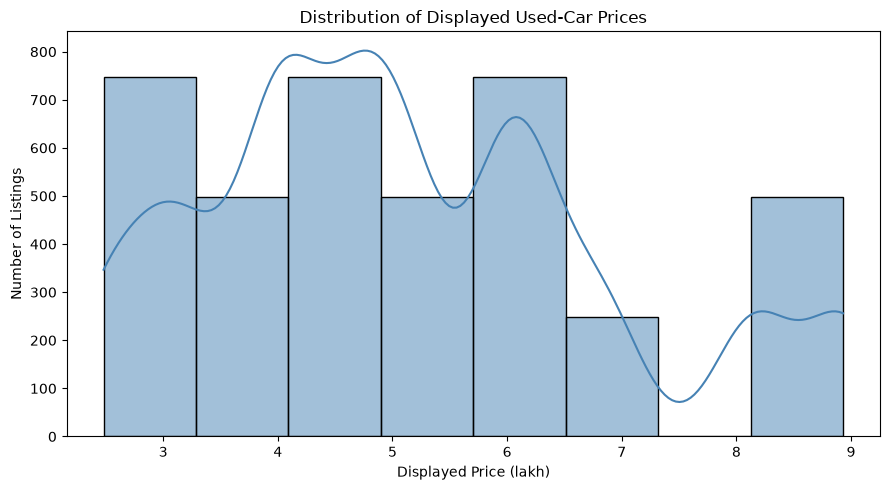

In [35]:
if "Display Price" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(data=df, x="Display Price", bins=min(8, max(3, df["Display Price"].dropna().nunique())), kde=True, color="steelblue")
    plt.title("Distribution of Displayed Used-Car Prices")
    plt.xlabel("Displayed Price (lakh)")
    plt.ylabel("Number of Listings")
    plt.tight_layout()
    plt.show()

## 11. Average price by company — horizontal bar chart

**Theory:** A horizontal bar chart makes it easier to compare brands. The chart displays the average displayed price for each company, ordered from highest to lowest. Use the listing-count table alongside it to avoid over-interpreting averages based on very few cars.

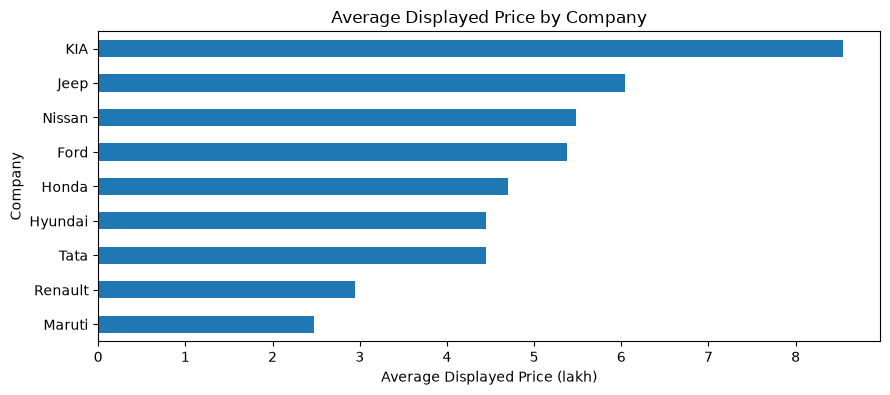

In [36]:
if {"Company", "Display Price"}.issubset(df.columns):
    company_avg = df.groupby("Company")["Display Price"].mean().sort_values()
    plt.figure(figsize=(9, max(4, 0.45 * len(company_avg))))
    company_avg.plot(kind="barh")
    plt.title("Average Displayed Price by Company")
    plt.xlabel("Average Displayed Price (lakh)")
    plt.ylabel("Company")
    plt.tight_layout()
    plt.show()

## 12. Listing counts by fuel type

**Theory:** A count plot compares the number of observations in each fuel category. This describes the composition of the current dataset, not the overall market share of each fuel type.

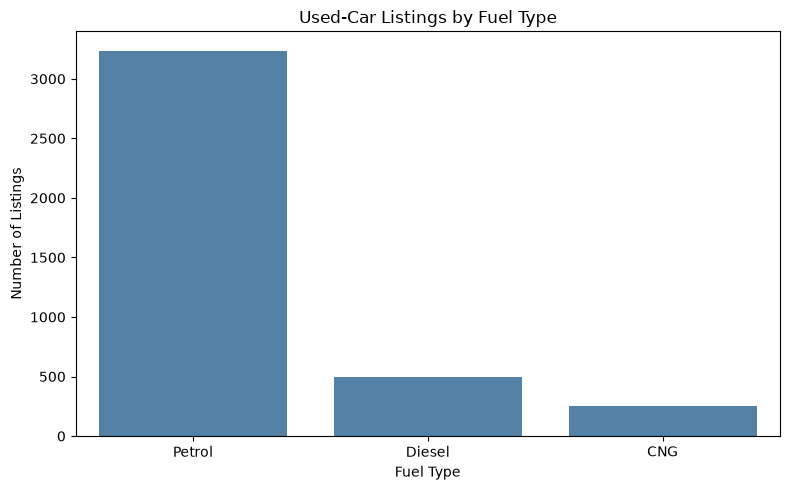

In [37]:
if "Fuel Type" in df.columns:
    plt.figure(figsize=(8, 5))
    order = df["Fuel Type"].value_counts().index
    sns.countplot(data=df, x="Fuel Type", order=order, color="steelblue")
    plt.title("Used-Car Listings by Fuel Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Number of Listings")
    plt.tight_layout()
    plt.show()

## 13. Displayed price by fuel type — box plot

**Theory:** A box plot compares the median, spread, and possible outliers of prices across categories. The chart can show whether one fuel category tends to have higher-priced listings in this sample, but sample sizes may be small.

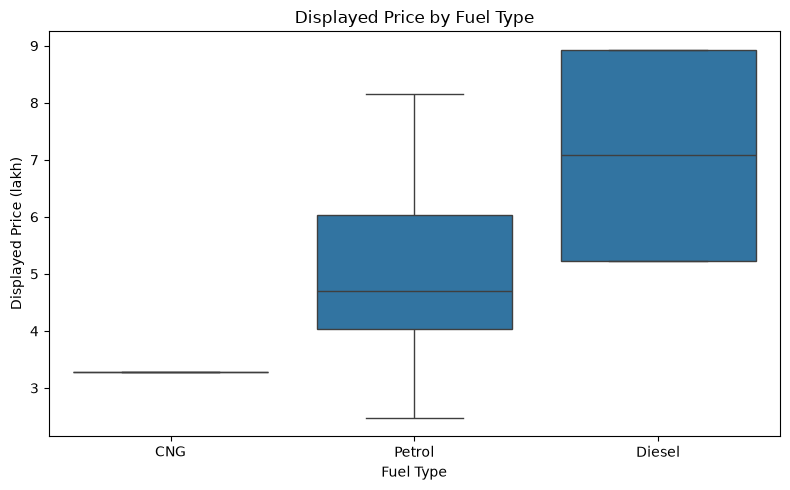

In [38]:
if {"Fuel Type", "Display Price"}.issubset(df.columns):
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="Fuel Type", y="Display Price")
    plt.title("Displayed Price by Fuel Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Displayed Price (lakh)")
    plt.tight_layout()
    plt.show()

## 14. Running distance vs displayed price — scatter plot

**Theory:** A scatter plot places one listing at each mileage-price pair. It helps inspect whether higher running is associated with lower prices. The relationship may also depend on model year, brand, and condition, so correlation is not causation.

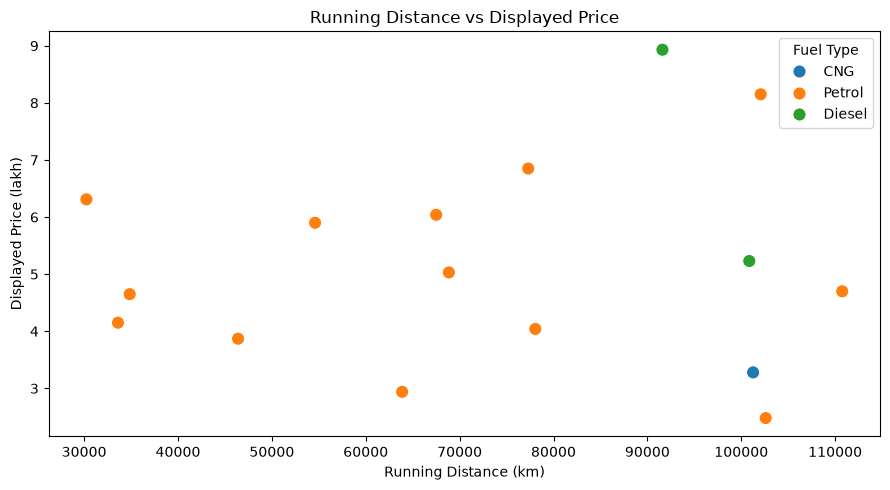

In [39]:
if {"Running", "Display Price"}.issubset(df.columns):
    plot_df = df.dropna(subset=["Running", "Display Price"])
    plt.figure(figsize=(9, 5))
    if "Fuel Type" in plot_df.columns:
        sns.scatterplot(data=plot_df, x="Running", y="Display Price", hue="Fuel Type", s=90)
    else:
        sns.scatterplot(data=plot_df, x="Running", y="Display Price", s=90)
    plt.title("Running Distance vs Displayed Price")
    plt.xlabel("Running Distance (km)")
    plt.ylabel("Displayed Price (lakh)")
    plt.tight_layout()
    plt.show()

## 15. Vehicle age vs displayed price — scatter plot

**Theory:** Vehicle age is approximated by current year minus model year. A scatter plot helps explore whether newer cars have higher displayed prices. This is only a rough comparison because vehicle model, trim, mileage, and condition differ.

In [40]:
if {"Vehicle Age", "Display Price"}.issubset(df.columns):
    plot_df = df.dropna(subset=["Vehicle Age", "Display Price"])
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=plot_df, x="Vehicle Age", y="Display Price", hue="Transmission" if "Transmission" in plot_df.columns else None, s=90)
    plt.title("Vehicle Age vs Displayed Price")
    plt.xlabel("Approximate Vehicle Age (years)")
    plt.ylabel("Displayed Price (lakh)")
    plt.tight_layout()
    plt.show()

## 16. Discount analysis

**Theory:** Discount amount and discount percentage answer different questions. Amount shows the absolute difference in lakh units; percentage compares the discount relative to the reference price. This chart helps compare how large the displayed reductions are.

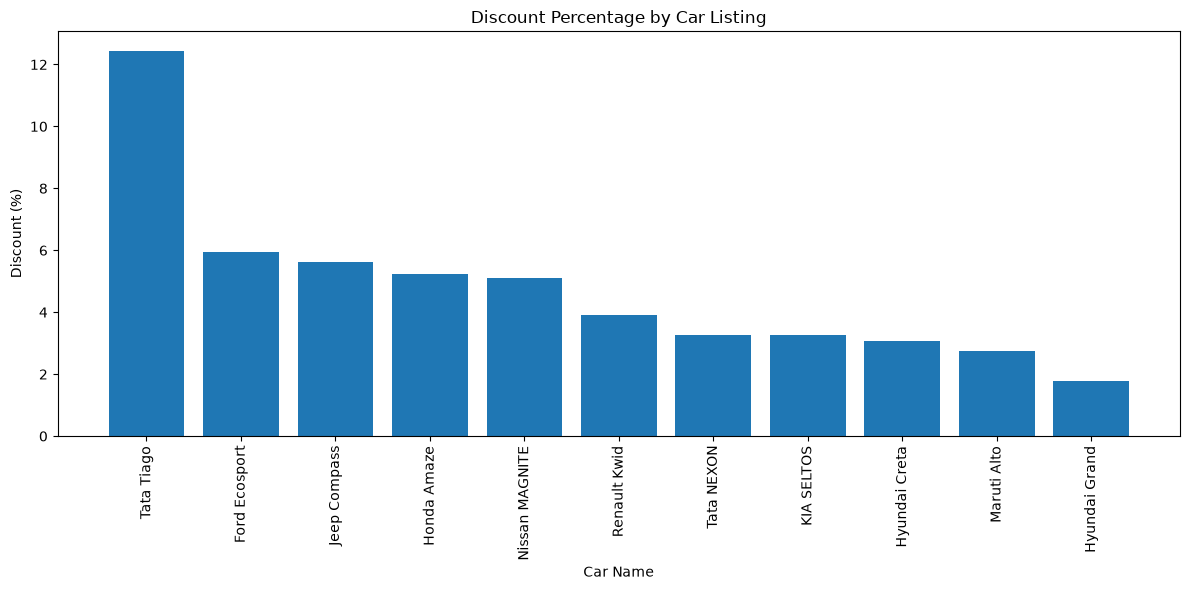

In [49]:
# Bar Chart: Discount Percentage by Car

if "Discount %" in df.columns:

    discount_df = df.dropna(subset=["Discount %"]).copy()
    discount_df = discount_df.sort_values("Discount %", ascending=False)

    labels = (
        discount_df["Car Name"].astype(str)
        if "Car Name" in discount_df.columns
        else discount_df.index.astype(str)
    )

    plt.figure(figsize=(12, 6))

    plt.bar(labels, discount_df["Discount %"])

    plt.title("Discount Percentage by Car Listing")
    plt.xlabel("Car Name")
    plt.ylabel("Discount (%)")

    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

else:
    print("Discount % column not found.")

## 17. EMI vs displayed price

**Theory:** This scatter plot explores whether higher displayed prices are associated with higher monthly EMI values. EMI also depends on loan duration, interest rate, down payment, and lender terms, which are not included in this dataset.

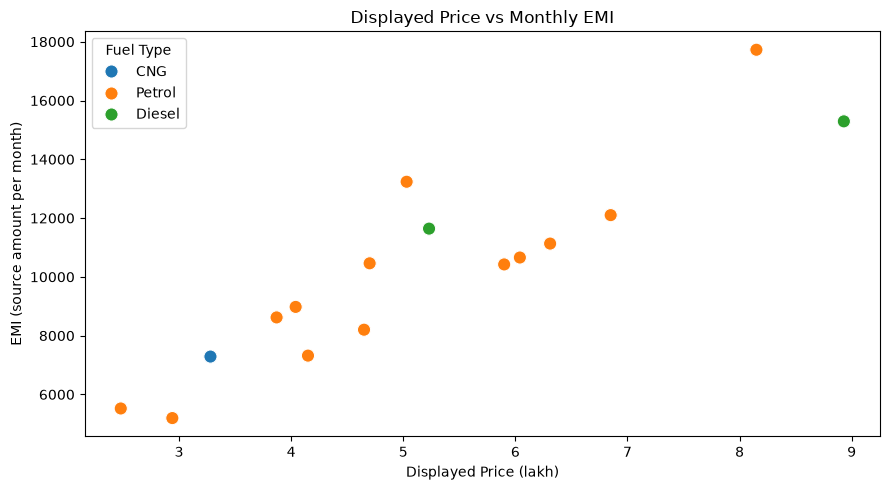

In [42]:
if {"EMI", "Display Price"}.issubset(df.columns):
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=df, x="Display Price", y="EMI", hue="Fuel Type" if "Fuel Type" in df.columns else None, s=90)
    plt.title("Displayed Price vs Monthly EMI")
    plt.xlabel("Displayed Price (lakh)")
    plt.ylabel("EMI (source amount per month)")
    plt.tight_layout()
    plt.show()

## 18. Listings by city

**Theory:** A city count plot identifies where the observed listings are located. It describes only the locations captured in this dataset and should not be interpreted as a ranking of city-wide supply.

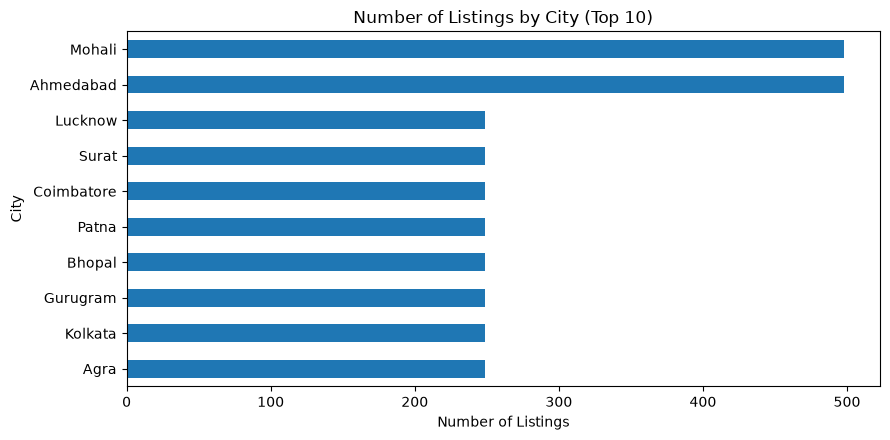

In [43]:
if "City" in df.columns:
    city_counts = df["City"].value_counts().head(10).sort_values()
    plt.figure(figsize=(9, max(4, 0.45 * len(city_counts))))
    city_counts.plot(kind="barh")
    plt.title("Number of Listings by City (Top 10)")
    plt.xlabel("Number of Listings")
    plt.ylabel("City")
    plt.tight_layout()
    plt.show()

## 19. Correlation analysis

**Theory:** Correlation measures the strength and direction of a linear relationship between numeric variables. Values near +1 indicate positive association, values near -1 indicate negative association, and values near 0 indicate little linear association. With only 14 listings, correlations can change substantially when new rows are added.

,Price,Display Price,Discount,Discount %,Running,EMI
Price,1.00,1.00,0.05,-0.30,0.06,0.89
Display Price,1.00,1.00,-0.03,-0.37,0.08,0.91
Discount,0.05,-0.03,1.00,0.92,-0.21,-0.15
Discount %,-0.30,-0.37,0.92,1.00,-0.18,-0.44
Running,0.06,0.08,-0.21,-0.18,1.00,0.26
EMI,0.89,0.91,-0.15,-0.44,0.26,1.00


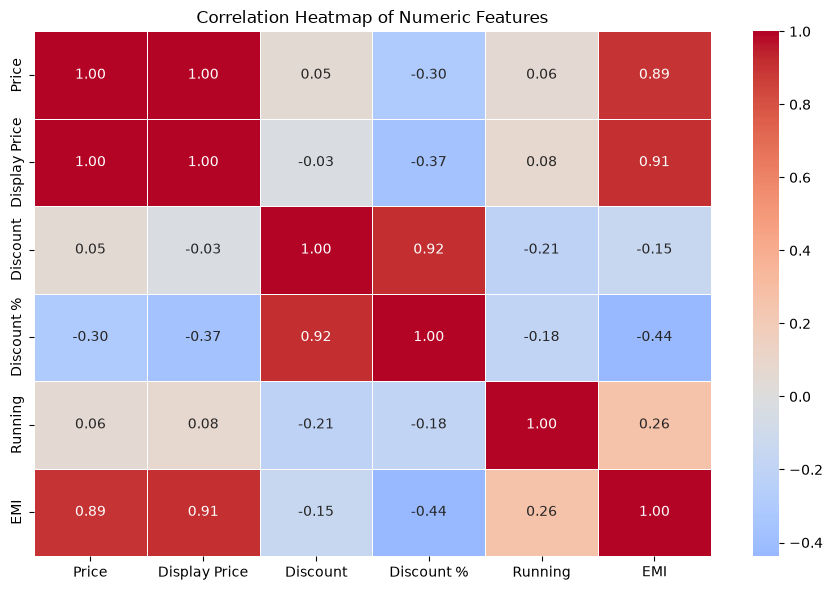

In [44]:
corr_cols = [c for c in ["Price", "Display Price", "Discount", "Discount %", "Running", "EMI", "Model Year", "Vehicle Age"]
             if c in df.columns]
corr_df = df[corr_cols].corr(numeric_only=True)
display(corr_df.round(2))

plt.figure(figsize=(9, 6))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

## 20. Outlier review using the IQR method

**Theory:** The interquartile range (IQR) is Q3 minus Q1. Values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR are flagged as potential outliers. Outliers are not automatically errors; premium cars may legitimately have much higher prices.

In [45]:
for col in [c for c in ["Display Price", "Running", "EMI"] if c in df.columns]:
    s = df[col].dropna()
    if len(s) >= 4:
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flagged = df.loc[df[col].lt(lower) | df[col].gt(upper), [c for c in ["Car Name", col, "Company", "City"] if c in df.columns]]
        print(f"{col}: IQR lower bound={lower:.2f}, upper bound={upper:.2f}; flagged rows={len(flagged)}")
        display(flagged)

Display Price: IQR lower bound=0.83, upper bound=9.27; flagged rows=0


,Car Name,Display Price,Company,City


Running: IQR lower bound=-20050.88, upper bound=173560.12; flagged rows=0


,Car Name,Running,Company,City


EMI: IQR lower bound=2320.12, upper bound=17417.12; flagged rows=249


,Car Name,EMI,Company,City
15,KIA SELTOS,17727,KIA,Hyderabad
31,KIA SELTOS,17727,KIA,Hyderabad
47,KIA SELTOS,17727,KIA,Hyderabad
63,KIA SELTOS,17727,KIA,Hyderabad
79,KIA SELTOS,17727,KIA,Hyderabad
...,...,...,...,...
3919,KIA SELTOS,17727,KIA,Hyderabad
3935,KIA SELTOS,17727,KIA,Hyderabad
3951,KIA SELTOS,17727,KIA,Hyderabad
3967,KIA SELTOS,17727,KIA,Hyderabad


## 21. Key findings summary

**Theory:** A conclusion section should summarize results produced by the dataset, rather than making unsupported market-wide claims. The code below generates simple data-driven statements from the available rows.

In [46]:
print("KEY FINDINGS")
print("-" * 60)
print(f"Total unique listings analyzed: {len(df)}")

if "Display Price" in df.columns and df["Display Price"].notna().any():
    cheapest = df.loc[df["Display Price"].idxmin()]
    costliest = df.loc[df["Display Price"].idxmax()]
    print(f"Average displayed price: {df['Display Price'].mean():.2f} lakh")
    print(f"Median displayed price: {df['Display Price'].median():.2f} lakh")
    print(f"Lowest displayed price: {cheapest['Display Price']:.2f} lakh")
    print(f"Highest displayed price: {costliest['Display Price']:.2f} lakh")
    if "Car Name" in df.columns:
        print("Lowest-priced listing:", cheapest["Car Name"])
        print("Highest-priced listing:", costliest["Car Name"])

if "Discount %" in df.columns and df["Discount %"].notna().any():
    best_discount = df.loc[df["Discount %"].idxmax()]
    print(f"Largest discount percentage: {best_discount['Discount %']:.2f}%")
    if "Car Name" in df.columns:
        print("Listing with largest relative discount:", best_discount["Car Name"])

if "Fuel Type" in df.columns and df["Fuel Type"].notna().any():
    print("Most common fuel type:", df["Fuel Type"].mode().iloc[0])
if "Company" in df.columns and df["Company"].notna().any():
    print("Most frequently listed company:", df["Company"].mode().iloc[0])

print("\nInterpretation caution: this sample contains only 14 listings. Treat findings as exploratory.")

KEY FINDINGS
------------------------------------------------------------
Total unique listings analyzed: 3984
Average displayed price: 5.16 lakh
Median displayed price: 4.87 lakh
Lowest displayed price: 2.48 lakh
Highest displayed price: 8.93 lakh
Lowest-priced listing: Maruti Alto
Highest-priced listing: KIA SELTOS
Largest discount percentage: 12.45%
Listing with largest relative discount: Tata Tiago
Most common fuel type: Petrol
Most frequently listed company: Ford

Interpretation caution: this sample contains only 14 listings. Treat findings as exploratory.


## 22. Project conclusion

This EDA project inspects used-car listing data, standardizes data types, creates vehicle-age and discount features, compares listing prices across categories, and explores relationships among price, mileage, EMI, and age. The visualizations help identify patterns in the available sample. Since the dataset contains only 14 listings and does not include vehicle condition, ownership history, service records, or final sale prices, conclusions should be treated as preliminary rather than representative of the entire used-car market.